# Notebook 6 – Outlier Treatment
**File:** `06_Outlier_Treatment.ipynb`

## Learning objectives
By the end of this notebook, you will be able to:
- Understand outliers and distinguish them from data-entry errors.
- Detect unusual observations using IQR, Z-score, and percentile methods.
- Apply winsorization, capping, flooring, and transformations.
- Decide whether to remove, retain, cap, or transform an observation using context.

> **Important:** An outlier is not automatically a mistake. Do not remove every outlier. First investigate what the value represents and how it affects the business question or ML model.

## 1. What is an Outlier?

An **outlier** is an observation that is unusually far from most other observations in a dataset.

**Simple example:** Most employees earn between ₹20,000 and ₹60,000 per month, but one employee earns ₹5,00,000. This value is unusual compared with the others. It may be correct (for example, a senior executive) or it may be an entry error.

**Real-world examples**
- A bank transaction of ₹10,00,000 among transactions usually below ₹5,000.
- A house with an unusually high price in a neighborhood.
- A sensor reporting a temperature of 500°C when the device normally measures 15–45°C.

**Why it matters:** Extreme values can strongly affect averages, standard deviations, correlations, charts, and some machine-learning models.

## 2. Outlier vs Error

| Term | Meaning | Example |
|---|---|---|
| Outlier | Unusually high or low observation | A genuine ₹10 lakh transaction |
| Error | Incorrect value caused by a mistake | Age entered as 250 instead of 25 |

An error can appear as an outlier, but not every outlier is an error.

**Investigation checklist**
1. Check the source system or original record.
2. Check valid business limits and units.
3. Compare with related columns and similar records.
4. Ask a domain expert when possible.
5. Record the reason for the final treatment.

## 3. Create a Sample Dataset

We will use monthly employee salaries. The high salary may represent a senior employee, so we will investigate it instead of automatically deleting it.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

salary_data = pd.DataFrame({
    "employee": [f"E{i:02d}" for i in range(1, 16)],
    "salary": [22000, 24000, 25000, 26000, 27000,
               28000, 29000, 30000, 31000, 32000,
               33000, 34000, 35000, 36000, 250000]
})

salary_data

,employee,salary
0,E01,22000
1,E02,24000
2,E03,25000
3,E04,26000
4,E05,27000
5,E06,28000
6,E07,29000
7,E08,30000
8,E09,31000
9,E10,32000


## 4. Visualize Possible Outliers

A box plot shows the median, quartiles, whiskers, and possible outliers. A point outside the whiskers is flagged by the box-plot rule; it is not automatically an error.

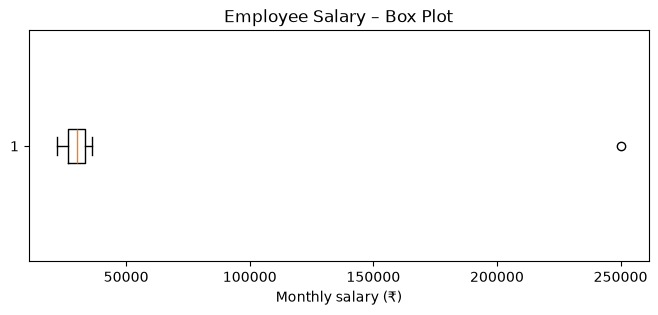

In [11]:
plt.figure(figsize=(8, 3))
plt.boxplot(salary_data["salary"], orientation = "horizontal")
plt.title("Employee Salary – Box Plot")
plt.xlabel("Monthly salary (₹)")
plt.show()

## 5. IQR Method

The **Interquartile Range (IQR)** measures the spread of the middle 50% of the data.

- Q1 = 25th percentile
- Q3 = 75th percentile
- IQR = Q3 − Q1
- Lower fence = Q1 − 1.5 × IQR
- Upper fence = Q3 + 1.5 × IQR

Values below the lower fence or above the upper fence are flagged as potential outliers.

**When useful:** A common, easy-to-understand method that does not require normally distributed data.

In [5]:
q1 = salary_data["salary"].quantile(0.25)
q3 = salary_data["salary"].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

iqr_outliers = salary_data[
    (salary_data["salary"] < lower_fence) |
    (salary_data["salary"] > upper_fence)
]

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Lower fence:", lower_fence)
print("Upper fence:", upper_fence)
print("\nPotential outliers:")
display(iqr_outliers)

Q1: 26500.0
Q3: 33500.0
IQR: 7000.0
Lower fence: 16000.0
Upper fence: 44000.0

Potential outliers:


,employee,salary
14,E15,250000


## 6. Z-Score Method

A **Z-score** describes how many standard deviations a value is from the mean. A large positive score is far above the mean; a large negative score is far below it.

A common rule flags values with an absolute Z-score greater than 3. This is a guideline, not a universal rule. It is most interpretable when the distribution is roughly normal and can be distorted by extreme values themselves.

**When useful:** Numeric data that is approximately bell-shaped, especially when distance from the mean is meaningful.

In [6]:
mean_salary = salary_data["salary"].mean()
std_salary = salary_data["salary"].std(ddof=0)

salary_data["z_score"] = (
    salary_data["salary"] - mean_salary
) / std_salary

z_outliers = salary_data[salary_data["z_score"].abs() > 3]

print("Mean:", round(mean_salary, 2))
print("Population standard deviation:", round(std_salary, 2))
display(salary_data[["employee", "salary", "z_score"]])
print("Values with |z-score| > 3:")
display(z_outliers)

Mean: 44133.33
Population standard deviation: 55166.25


,employee,salary,z_score
0,E01,22000,-0.401211
1,E02,24000,-0.364957
2,E03,25000,-0.346830
3,E04,26000,-0.328703
4,E05,27000,-0.310576
5,E06,28000,-0.292449
6,E07,29000,-0.274322
7,E08,30000,-0.256195
8,E09,31000,-0.238068
9,E10,32000,-0.219941


Values with |z-score| > 3:


,employee,salary,z_score
14,E15,250000,3.73175


## 7. Percentile Method

The percentile method uses selected cutoffs, such as the 1st and 99th percentiles. Values below or above those cutoffs are flagged.

**When useful:** Large datasets where a business rule such as “investigate the highest 1%” makes sense. The percentile choice should be justified by the task, not selected only to make inconvenient values disappear.

In [7]:
lower_percentile = salary_data["salary"].quantile(0.01)
upper_percentile = salary_data["salary"].quantile(0.99)

percentile_outliers = salary_data[
    (salary_data["salary"] < lower_percentile) |
    (salary_data["salary"] > upper_percentile)
]

print("1st percentile:", lower_percentile)
print("99th percentile:", upper_percentile)
display(percentile_outliers)

1st percentile: 22280.0
99th percentile: 220039.99999999988


,employee,salary,z_score
0,E01,22000,-0.401211
14,E15,250000,3.731750


## 8. Winsorization

**Winsorization** replaces values beyond chosen percentile limits with the limit values. It retains the rows but reduces the influence of extreme observations.

For example, values above the 95th percentile are replaced by the 95th-percentile value.

**Use carefully:** It changes the original measurements. Keep the original column and create a separate treated column so that the change is traceable.

In [ ]:
lower_limit = salary_data["salary"].quantile(0.05)
upper_limit = salary_data["salary"].quantile(0.95)

salary_data["salary_winsorized"] = salary_data["salary"].clip(
    lower=lower_limit,
    upper=upper_limit
)

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
display(salary_data[["employee", "salary", "salary_winsorized"]])

## 9. Capping and Flooring

- **Capping:** Replace values above a chosen upper limit with that limit.
- **Flooring:** Replace values below a chosen lower limit with that limit.
- **Clipping:** Apply both a lower and an upper limit.

These methods preserve the number of rows but alter extreme values. Choose limits using domain knowledge or a documented statistical rule.

In [ ]:
lower_cap = salary_data["salary"].quantile(0.05)
upper_cap = salary_data["salary"].quantile(0.95)

salary_data["salary_capped"] = salary_data["salary"].clip(upper=upper_cap)
salary_data["salary_floored"] = salary_data["salary"].clip(lower=lower_cap)
salary_data["salary_capped_and_floored"] = salary_data["salary"].clip(
    lower=lower_cap, upper=upper_cap
)

display(salary_data[[
    "employee", "salary", "salary_capped",
    "salary_floored", "salary_capped_and_floored"
]])

## 10. Transformation

A transformation changes the scale or shape of a feature. A log transformation can reduce right skew when values are positive.

**Example:** Income and transaction amounts often have a long right tail. `np.log1p(x)` calculates log(1 + x), which also works when x is zero.

**Important:** Transformation does not prove that a value is invalid, and it does not always remove outliers. Interpret transformed values carefully. Do not use a log transform on negative values without choosing an appropriate method.

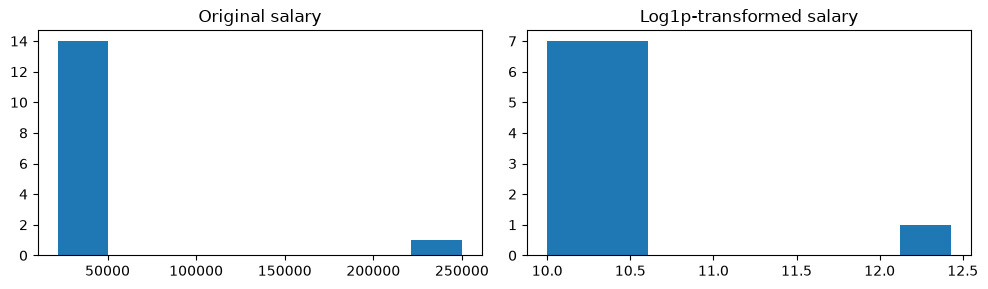

In [8]:
positive_values = salary_data["salary"].clip(lower=0)
salary_data["salary_log1p"] = np.log1p(positive_values)

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(salary_data["salary"], bins=8)
axes[0].set_title("Original salary")
axes[1].hist(salary_data["salary_log1p"], bins=8)
axes[1].set_title("Log1p-transformed salary")
plt.tight_layout()
plt.show()

## 11. Removing Outliers

Removing a row may be appropriate when the value is confirmed to be invalid, is not recoverable, and cannot be corrected reliably.

**Example:** A person's age is recorded as 250 because of a typing error, and the source record confirms the correct value is unavailable.

Do not remove a genuine high-value customer, expensive house, or large bank transaction merely because it is rare. Removing valid extremes can bias analysis and hide important business cases.

In [9]:
# Demonstration only: remove rows flagged by the IQR rule.
# Do this only after confirming that removal is justified.
salary_without_flagged = salary_data[
    salary_data["salary"].between(lower_fence, upper_fence)
].copy()

print("Original row count:", len(salary_data))
print("Rows after IQR-based filtering:", len(salary_without_flagged))

Original row count: 15
Rows after IQR-based filtering: 14


## 12. Retaining Outliers

Retain an outlier when it is a valid observation and important to the problem.

Examples:
- Fraud detection: unusual transactions may be the most important records.
- Equipment monitoring: extreme readings may signal a real failure.
- High-income analysis: the highest incomes are part of the population being studied.

Possible actions include retaining the value, adding an outlier flag, using robust statistics, or choosing a model less sensitive to extreme values.

In [10]:
salary_data["is_iqr_outlier"] = (
    (salary_data["salary"] < lower_fence) |
    (salary_data["salary"] > upper_fence)
)

display(salary_data[["employee", "salary", "is_iqr_outlier"]])

,employee,salary,is_iqr_outlier
0,E01,22000,False
1,E02,24000,False
2,E03,25000,False
3,E04,26000,False
4,E05,27000,False
5,E06,28000,False
6,E07,29000,False
7,E08,30000,False
8,E09,31000,False
9,E10,32000,False


## 13. Outlier Decision Table

For every detected value, answer these questions before treatment:

| Question | Example decision |
|---|---|
| Is it an error? | Check source; do not assume |
| Is it a valid extreme observation? | Confirm with domain context |
| Should it be removed? | Only if invalid and not recoverable |
| Should it be capped? | If extreme influence is harmful and a cap is justified |
| Should it be transformed? | If scale/skew is an issue and transformation fits the model |
| Why? | Record evidence and business reasoning |

**Example review:** The ₹2,50,000 salary is unusual. If payroll confirms it belongs to a senior employee, it is a valid extreme observation. Retain it for salary analysis; consider a log transform for a model that benefits from reduced skew. Do not delete it simply because IQR flags it.

In [ ]:
# A simple, auditable review log. Update the decision after checking the source.
review_log = pd.DataFrame({
    "value": [250000],
    "is_error": ["Not confirmed"],
    "valid_extreme_observation": ["Possible; verify with payroll"],
    "action": ["Retain pending verification"],
    "reason": ["A high salary may be valid for a senior employee"]
})

display(review_log)

## 14. Business and AI/ML Use Cases

- **Banking:** Keep unusual transactions for fraud investigation; do not remove them from a fraud dataset without a reason.
- **Retail:** Investigate unusually large orders; they may be wholesale orders or data errors.
- **Healthcare:** Verify extreme lab measurements; they may be clinically important or a measurement issue.
- **Machine learning:** Linear regression and distance-based methods can be sensitive to extreme values. Tree-based models are often less sensitive to feature scale, but still need data-quality checks.

## 15. Best Practices

1. Detect potential outliers using more than one view when appropriate.
2. Investigate the source and domain meaning.
3. Separate confirmed errors from valid extremes.
4. Keep original columns and create treated columns.
5. Fit treatment limits on training data only, then apply the same limits to validation/test data to avoid data leakage.
6. Document every decision and compare model performance before and after treatment.

## 16. Mini Practice

1. What is the difference between an outlier and an error?
2. Explain Q1, Q3, and IQR.
3. When is the Z-score method appropriate?
4. What is the difference between capping and flooring?
5. Why can removing outliers create bias?
6. Give one example where an outlier should be retained.
7. Why should treatment limits be learned from training data only?